# AQUA — Ganga Water-Quality Forecasting Pipeline
**B.Tech minor project | Reproducible modelling notebook**

This notebook builds separate next-observation forecasting models for **Biochemical Oxygen Demand (BOD)**, **Dissolved Oxygen (DO)**, and **pH** from the supplied CWC chemical, biological, and physical surface-water-quality CSVs.

- Temporal evaluation: **training 2021–2023, validation 2024, final test 2025**.
- Forecast unit: the **next eligible observed sample at a station**, not a daily forecast.
- Predictors are lagged within each station; current/future measurements are not used as predictors.
- Median imputation is fitted inside each scikit-learn pipeline on training data only.
- Outputs are saved under `artifacts/ganga/`. This notebook does not overwrite the separate Yamuna model artefacts.

**Station-selection caution:** the source `Basin`/`River` fields can say `Ganga` even when `Local River` is `Yamuna` or another tributary. The default rule below selects records whose `Local River` metadata identifies the Ganga main stem. Review the generated station inventory and configure an explicit station allowlist if your project supervisor has approved a different set.

## 1. Environment setup and imports

Run this notebook in VS Code with a Python environment that has Jupyter support. The optional install cell uses `%pip` and does not force a reinstall when packages are already available.

In [1]:
# If needed, uncomment and run once in this notebook's selected environment:
# %pip install pandas numpy matplotlib scikit-learn joblib nbformat

import json
import os
import re
import warnings
import zipfile
from pathlib import Path
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 2.3.3
NumPy: 2.3.5
scikit-learn: 1.7.2


## 2. Configuration and file paths

Set `DATA_DIR` to the folder containing the three CSV files. The default uses the current user's Documents folder without hardcoding a Windows username. If your files are elsewhere, edit only this cell.

`GANGA_STATION_ALLOWLIST` is optional. Leave it as `None` to use the conservative metadata rule (`Local River` equals Ganga). If you set a list, use exact station names from the inventory and only include stations your project team has confirmed as Ganga main-stem stations.

In [2]:

from pathlib import Path

# ============================================================
# CONFIGURATION — AQUA GANGA MODEL
# ============================================================

RANDOM_STATE = 42

# Your folder is named AQUA_DATA (not AQUA_Data).
# Check common Windows locations and use the first one
# containing all three required CSV files.

CSV_FILES = {
    "physical": "swq_physical_parameter_manual_cwc_up_2021_2025.csv",
    "chemical": "swq_chemical_parameter_manual_cwc_up_2021_2025.csv",
    "biological": "swq_biological_parameter_manual_cwc_up_2021_2025.csv",
}

home = Path.home()

candidate_dirs = [
    home / "Documents" / "AQUA_DATA",
    home / "OneDrive" / "Documents" / "AQUA_DATA",
    home / "Desktop" / "AQUA_DATA",
    Path.cwd() / "AQUA_DATA",
    Path.cwd(),
]

# Find a directory containing every required CSV.
DATA_DIR = None

for folder in candidate_dirs:
    if folder.is_dir() and all(
        (folder / filename).is_file()
        for filename in CSV_FILES.values()
    ):
        DATA_DIR = folder
        break

# If the files are not all together, report what Python can see.
if DATA_DIR is None:
    print("Could not find all three CSV files in the usual locations.")
    print("\nChecked locations:")
    for folder in candidate_dirs:
        print(f"  {folder} | exists: {folder.is_dir()}")

    print("\nCSV files found inside Documents/AQUA_DATA:")
    search_root = home / "Documents" / "AQUA_DATA"

    if search_root.is_dir():
        for file in search_root.rglob("*.csv"):
            print(" ", file)
    else:
        print("  That folder was not found.")

    raise FileNotFoundError(
        "\nPlease check the paths and filenames printed above."
    )

# Output files will be saved inside the notebook's working directory.
OUTPUT_DIR = Path("artifacts") / "ganga"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Station selection: None means use metadata-based selection.
GANGA_STATION_ALLOWLIST = None

# Retain consecutive observations 7–14 days apart.
MIN_GAP_DAYS = 7
MAX_GAP_DAYS = 14

SPLIT_YEARS = {
    "train_end": 2023,
    "validation": 2024,
    "test": 2025,
}

RF_PARAMS = {
    "n_estimators": 200,
    "max_depth": 10,
    "min_samples_leaf": 1,
    "max_features": 1.0,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

TARGETS = {
    "BOD": {
        "column": "Biochemical Oxygen Demand (mg/L)",
        "unit": "mg/L",
    },
    "DO": {
        "column": "Dissolved oxygen (mg/L)",
        "unit": "mg/L",
    },
    "pH": {
        "column": "Potential of Hydrogen (pH)",
        "unit": "pH",
    },
}

print("Data directory:", DATA_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())
print("\nRequired CSV files:")

for key, filename in CSV_FILES.items():
    print(f"  ✓ {key}: {filename}")


Data directory: C:\Users\ashma\OneDrive\Documents\AQUA_Data
Output directory: C:\Users\ashma\Downloads\artifacts\ganga

Required CSV files:
  ✓ physical: swq_physical_parameter_manual_cwc_up_2021_2025.csv
  ✓ chemical: swq_chemical_parameter_manual_cwc_up_2021_2025.csv
  ✓ biological: swq_biological_parameter_manual_cwc_up_2021_2025.csv


## 3. Load the three source CSVs

In [3]:
physical_raw = pd.read_csv(DATA_DIR / CSV_FILES["physical"], low_memory=False)
chemical_raw = pd.read_csv(DATA_DIR / CSV_FILES["chemical"], low_memory=False)
biological_raw = pd.read_csv(DATA_DIR / CSV_FILES["biological"], low_memory=False)

for name, frame in [
    ("Physical", physical_raw), ("Chemical", chemical_raw), ("Biological", biological_raw)
]:
    print(f"{name}: {frame.shape[0]:,} rows × {frame.shape[1]} columns")

Physical: 12,173 rows × 25 columns
Chemical: 12,178 rows × 52 columns
Biological: 12,064 rows × 23 columns


## 4. Inspect schema and validate required keys

In [4]:
KEYS = ["Station", "Data Acquisition Time"]
required = set(KEYS)
for name, frame in [("physical", physical_raw), ("chemical", chemical_raw), ("biological", biological_raw)]:
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{name} CSV is missing required columns: {sorted(missing)}")
    print(f"\n{name.upper()} columns ({len(frame.columns)}):")
    print(frame.columns.tolist())

print("\nTarget source-column check:")
for label, spec in TARGETS.items():
    print(f"{label}: {spec['column']!r} in biological/chemical =",
          spec["column"] in biological_raw.columns or spec["column"] in chemical_raw.columns)


PHYSICAL columns (25):
['SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River', 'Latitude', 'Longitude', 'Data Acquisition Time', 'Electric Conductivity (μS/cm)', 'Colour', 'Odour', 'Turbidity (NTU)', 'Temperature (ºC)', 'Total Solids (mg/L)']

CHEMICAL columns (52):
['SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River', 'Latitude', 'Longitude', 'Data Acquisition Time', 'Amonia N (mgN/L)', 'Boron (mg/L)', 'Carbonate (mg/L)', 'Calcium (mg/L)', 'Chloride (mg/L)', 'Dissolved oxygen (mg/L)', 'Total Dissolved Solids (mg/L)', 'Fluoride (mg/L)', 'Bicarbonate (mg/L)', 'Potassium (mg/L)', 'Magnesium (mg/L)', 'Sodium (mg/L)', 'Nitrite N+Nitrate N (mgN/L)', 'Potential of Hydrogen (pH)', 'Sulphate (mg/L)', 'Tota

## 5. Parse timestamps and handle duplicate station-time records

The source uses strings such as `01-01-2021 09:40` (day-month-year hour:minute). Parsing first tries that format and then falls back to pandas' robust parser for any variations. Invalid timestamps and blank station keys are reported and excluded. Duplicate station-time records are consolidated before merging to prevent many-to-many row multiplication: numeric measurement columns use the median, while metadata uses the first non-null value.

In [5]:
def parse_source_timestamps(series):
    parsed = pd.to_datetime(series, format="%d-%m-%Y %H:%M", errors="coerce")
    remaining = parsed.isna() & series.notna()
    if remaining.any():
        parsed.loc[remaining] = pd.to_datetime(series.loc[remaining], errors="coerce", dayfirst=True)
    return parsed

METADATA_COLS = [
    "Agency", "State", "District", "River", "Basin", "Tributary",
    "Subtributary", "SubSubtributary", "Local River", "Latitude", "Longitude"
]

def prepare_source(frame, source_name):
    out = frame.copy()
    out["Station"] = out["Station"].astype("string").str.strip()
    out["Data Acquisition Time"] = parse_source_timestamps(out["Data Acquisition Time"])
    invalid_time = int(out["Data Acquisition Time"].isna().sum())
    invalid_station = int(out["Station"].isna().sum() + (out["Station"].fillna("").str.strip() == "").sum())
    print(f"{source_name}: invalid timestamps={invalid_time:,}; missing/blank station keys={invalid_station:,}")
    out = out.dropna(subset=KEYS)
    out = out[out["Station"].astype(str).str.strip().ne("")].copy()
    dup_rows = int(out.duplicated(KEYS, keep=False).sum())
    print(f"{source_name}: rows participating in duplicate station-time keys={dup_rows:,}")
    value_cols = [c for c in out.columns if c not in KEYS and c not in ["SlNo"]]
    agg = {}
    for col in value_cols:
        if pd.api.types.is_numeric_dtype(out[col]):
            agg[col] = "median"
        else:
            agg[col] = "first"
    out = out.groupby(KEYS, as_index=False, dropna=False).agg(agg)
    return out

physical = prepare_source(physical_raw, "Physical")
chemical = prepare_source(chemical_raw, "Chemical")
biological = prepare_source(biological_raw, "Biological")

Physical: invalid timestamps=0; missing/blank station keys=0
Physical: rows participating in duplicate station-time keys=0
Chemical: invalid timestamps=0; missing/blank station keys=0
Chemical: rows participating in duplicate station-time keys=0
Biological: invalid timestamps=0; missing/blank station keys=0
Biological: rows participating in duplicate station-time keys=0


## 6. Merge chemical, biological, and physical measurements

In [6]:
# Preserve the original notebook's inner-join methodology: only station-time keys
# represented in all three source tables enter the combined modelling dataset.
# Keep physical metadata as the preferred canonical metadata source.
measurement_cols = {
    "physical": [c for c in physical.columns if c not in KEYS and c not in METADATA_COLS and c != "SlNo"],
    "chemical": [c for c in chemical.columns if c not in KEYS and c not in METADATA_COLS and c != "SlNo"],
    "biological": [c for c in biological.columns if c not in KEYS and c not in METADATA_COLS and c != "SlNo"],
}
physical_keep = KEYS + [c for c in METADATA_COLS if c in physical.columns] + measurement_cols["physical"]
chemical_keep = KEYS + measurement_cols["chemical"]
biological_keep = KEYS + measurement_cols["biological"]

merged = chemical[chemical_keep].merge(
    biological[biological_keep], on=KEYS, how="inner", validate="one_to_one"
)
merged = merged.merge(
    physical[physical_keep], on=KEYS, how="inner", validate="one_to_one"
)
merged = merged.sort_values(["Station", "Data Acquisition Time"]).reset_index(drop=True)

print("Deduplicated source rows:", {
    "chemical": len(chemical), "biological": len(biological), "physical": len(physical)
})
print("Rows after all-three inner merge:", len(merged))
print("Unique station-time pairs:", merged[KEYS].drop_duplicates().shape[0])
print("Merged shape:", merged.shape)
display(merged.head())

Deduplicated source rows: {'chemical': 12178, 'biological': 12064, 'physical': 12173}
Rows after all-three inner merge: 12062
Unique station-time pairs: 12062
Merged shape: (12062, 71)


,Station,Data Acquisition Time,State LGD Code_x,District LGD Code_x,Tehsil_x,Block_x,Village_x,Amonia N (mgN/L),Boron (mg/L),Carbonate (mg/L),...,District LGD Code,Tehsil,Block,Village,Electric Conductivity (μS/cm),Colour,Odour,Turbidity (NTU),Temperature (ºC),Total Solids (mg/L)
0,AGRA (J.B.),2021-01-01 09:40:00,9.0,118.0,AGRA,-,-,15.13,NaN,0.0,...,118.0,AGRA,-,-,1520.0,None,None,4.0,13.0,NaN
1,AGRA (J.B.),2021-02-01 09:00:00,9.0,118.0,AGRA,-,-,17.89,NaN,0.0,...,118.0,AGRA,-,-,1605.0,Light Brown,odour free,1.0,14.0,NaN
2,AGRA (J.B.),2021-03-01 08:30:00,9.0,118.0,AGRA,-,-,17.11,NaN,0.0,...,118.0,AGRA,-,-,1510.0,None,None,1.0,21.0,NaN
3,AGRA (J.B.),2021-03-22 08:00:00,9.0,118.0,AGRA,-,-,11.82,NaN,0.0,...,118.0,AGRA,-,-,1510.0,Light Brown,Oder Free,4.0,24.0,NaN
4,AGRA (J.B.),2021-04-05 08:15:00,9.0,118.0,AGRA,-,-,17.11,NaN,0.0,...,118.0,AGRA,-,-,1610.0,Light Brown,Oder Free,11.0,26.0,NaN


## 7. Station and river-metadata inventory

Do not use `River == Ganga` or `Basin == Ganga` alone as proof that a station is on the Ganga main stem. The attached CWC files show those fields can be broad basin labels while `Local River` names Yamuna or another tributary. Review the inventory and the chosen rule below before interpreting model results.

In [7]:
river_cols = [c for c in ["River", "Basin", "Tributary", "Subtributary", "SubSubtributary", "Local River"] if c in merged.columns]
meta_cols = [c for c in ["Station", *river_cols, "Latitude", "Longitude"] if c in merged.columns]
station_inventory = (
    merged.groupby("Station", dropna=False)
    .agg(
        **{c.replace(" ", "_").replace("/", "_"): (c, "first") for c in meta_cols if c != "Station"},
        observation_count=("Data Acquisition Time", "size"),
        first_observation=("Data Acquisition Time", "min"),
        last_observation=("Data Acquisition Time", "max"),
    )
    .reset_index()
)
display(station_inventory.sort_values("Station"))
print("\nLocal River values:")
if "Local River" in merged.columns:
    display(merged["Local River"].fillna("<missing>").astype(str).value_counts().head(30).rename_axis("Local River").to_frame("rows"))

,Station,River,Basin,Tributary,Subtributary,SubSubtributary,Local_River,Latitude,Longitude,observation_count,first_observation,last_observation
0,AGRA (J.B.),Ganga,Ganga,Yamuna,-,-,Yamuna,27.203889,78.035000,120,2021-01-01 09:40:00,2024-09-22 07:50:00
1,AGRA(POIYAGHAT),Ganga,Ganga,Yamuna,Yamuna,Yamuna,Yamuna,27.254167,78.023056,127,2021-01-01 08:00:00,2024-09-21 09:30:00
2,ARNOTA,Ganga,Ganga,Yamuna,Uttangan,-,Uttangan,26.962500,78.362500,4,2021-08-23 11:00:00,2022-10-21 11:30:00
3,AURAIYA,Ganga,Ganga,Yamuna,-,-,Yamuna,26.428056,79.478889,119,2021-01-01 09:10:00,2024-09-21 08:25:00
4,Akbarpur,Ganga,Ganga,Chhoti Saryu,-,-,Chhoti Saryu,26.429167,82.548611,117,2021-01-01 08:00:00,2024-06-21 07:10:00
...,...,...,...,...,...,...,...,...,...,...,...,...
90,UDI,Ganga,Ganga,Yamuna,Chambal,-,Chambal,26.696389,78.937778,119,2021-01-01 09:00:00,2024-08-21 08:55:00
91,V S Bridge,Ganga,Ganga,Ganga,Ganga,Ganga,Ganga,25.255278,83.025278,132,2021-01-01 11:35:00,2024-08-21 11:25:00
92,Varanasi,Ganga,Ganga,-,-,-,Ganga,25.325833,83.040000,132,2021-01-01 10:30:00,2024-08-21 10:45:00
93,Vrindavan-Yamuna ExpresswayLink Road Bridge U/...,Ganga,Ganga,Yamuna,Yamuna,Yamuna,Yamuna,27.565833,77.707778,64,2023-01-02 08:30:00,2024-11-21 08:30:00



Local River values:


,rows
Local River,
Ganga,3036
Yamuna,1723
Ghagra,862
Rapti,858
Gomti,811
Ramganga,571
Betwa,436
Kwano,428
Sai,391


## 8. Select the Ganga main-stem station set

In [8]:
def normalized_text(series):
    return series.fillna("").astype(str).str.strip().str.casefold()

if GANGA_STATION_ALLOWLIST is not None:
    selected_stations = sorted(set(map(str, GANGA_STATION_ALLOWLIST)))
    missing_names = sorted(set(selected_stations) - set(merged["Station"].astype(str).unique()))
    if missing_names:
        raise ValueError(f"Configured station names not found in merged data: {missing_names}")
    station_selection_rule = "Explicit GANGA_STATION_ALLOWLIST configured by project team"
else:
    if "Local River" not in merged.columns:
        raise ValueError("Cannot apply conservative Ganga selection: source has no 'Local River' metadata. Configure GANGA_STATION_ALLOWLIST after reviewing station inventory.")
    local_is_ganga = normalized_text(merged["Local River"]).isin(["ganga", "ganges"])
    selected_stations = sorted(merged.loc[local_is_ganga, "Station"].astype(str).unique())
    station_selection_rule = "Local River metadata equals Ganga/Ganges (case-insensitive)"

print("Selection rule:", station_selection_rule)
print("Selected stations:", len(selected_stations))
print("Selected station names:", selected_stations)
if not selected_stations:
    raise ValueError("No stations matched the configured Ganga main-stem rule. Review station_inventory and set GANGA_STATION_ALLOWLIST explicitly.")
model_source = merged[merged["Station"].astype(str).isin(selected_stations)].copy()
display(station_inventory[station_inventory["Station"].isin(selected_stations)].sort_values("Station"))

Selection rule: Local River metadata equals Ganga/Ganges (case-insensitive)
Selected stations: 23
Selected station names: ['Allahabad', 'Ankinghat', 'Baluaghat', 'Basantpur', 'Bhitaura', 'Bithoor', 'Fatehgarh', 'Garhmukteshwar', 'Ghazipur (Veer Abdul Hamid Bridge)', 'Jajmau', 'Kachhla Bridge', 'Kanpur', 'Katri Umrauli', 'Kazipura', 'Mehandipur', 'Mirzapur', 'Parmarth Ghat', 'SITAMARHI', 'Saidpur', 'Shahzadpur', 'Shastri Bridge', 'V S Bridge', 'Varanasi']


,Station,River,Basin,Tributary,Subtributary,SubSubtributary,Local_River,Latitude,Longitude,observation_count,first_observation,last_observation
5,Allahabad,Ganga,Ganga,Ganga,Ganga,Ganga,Ganga,25.403056,81.911389,133,2021-01-01 07:55:00,2024-08-21 08:25:00
6,Ankinghat,Ganga,Ganga,-,-,-,Ganga,26.933056,80.032778,144,2021-01-01 08:00:00,2025-03-21 09:00:00
12,Baluaghat,Ganga,Ganga,Ganga,Ganga,Ganga,Ganga,25.420833,83.183611,132,2021-01-01 13:50:00,2024-08-21 13:10:00
15,Basantpur,Ganga,Ganga,-,-,-,Ganga,29.103056,78.098611,144,2021-01-01 10:00:00,2025-03-21 08:00:00
19,Bhitaura,Ganga,Ganga,-,-,-,Ganga,26.041944,80.859444,144,2021-01-01 08:30:00,2025-03-21 08:55:00
21,Bithoor,Ganga,Ganga,-,-,-,Ganga,26.616872,80.275578,144,2021-01-01 12:00:00,2025-03-21 09:08:00
30,Fatehgarh,Ganga,Ganga,-,-,-,Ganga,27.401389,79.623056,142,2021-01-01 08:00:00,2025-03-21 08:55:00
32,Garhmukteshwar,Ganga,Ganga,-,-,-,Ganga,28.766389,78.141667,144,2021-01-01 10:30:00,2025-03-21 09:00:00
33,Ghazipur (Veer Abdul Hamid Bridge),Ganga,Ganga,Ganga,Ganga,Ganga,Ganga,25.585556,83.606667,123,2021-01-01 16:35:00,2024-08-21 16:00:00
39,Jajmau,Ganga,Ganga,-,-,-,Ganga,26.409444,80.443889,144,2021-01-01 09:30:00,2025-03-21 12:53:00


## 9. Data cleaning and target validation

Target measurements are cleaned independently. Non-numeric values become missing. pH values at or below 0 and above 14 are invalidated; zero values in other measurements are not automatically treated as missing. No undocumented outlier clipping/removal is applied.

In [9]:
required_targets = {label: spec["column"] for label, spec in TARGETS.items()}
for label, col in required_targets.items():
    if col not in model_source.columns:
        raise KeyError(f"Required target column for {label} not found: {col!r}. Inspect source schemas and update TARGETS only after confirming the correct source column.")
    model_source[col] = pd.to_numeric(model_source[col], errors="coerce")

# Numeric conversion for candidate predictor measurements; keep non-measurement metadata untouched.
candidate_measurements = []
for col in model_source.columns:
    if col in KEYS or col in METADATA_COLS or col == "SlNo":
        continue
    if pd.api.types.is_numeric_dtype(model_source[col]) or col in [
        "Electric Conductivity (μS/cm)", "Turbidity (NTU)", "Temperature (ºC)",
        "Total Solids (mg/L)", "Total Dissolved Solids (mg/L)", "Amonia N (mgN/L)",
        "Nitrate N (mgN/L)", "Sulphate (mg/L)"
    ] or col in required_targets.values():
        model_source[col] = pd.to_numeric(model_source[col], errors="coerce")
        candidate_measurements.append(col)

ph_col = TARGETS["pH"]["column"]
invalid_ph = model_source[ph_col].notna() & ((model_source[ph_col] <= 0) | (model_source[ph_col] > 14))
print("Invalid pH values set to missing:", int(invalid_ph.sum()))
model_source.loc[invalid_ph, ph_col] = np.nan

print("Rows after station selection:", len(model_source))
print("\nTarget missingness before lag construction:")
display(pd.DataFrame({
    "target": list(required_targets),
    "column": list(required_targets.values()),
    "non_missing": [int(model_source[c].notna().sum()) for c in required_targets.values()],
    "missing": [int(model_source[c].isna().sum()) for c in required_targets.values()],
}))

Invalid pH values set to missing: 0
Rows after station selection: 3036

Target missingness before lag construction:


,target,column,non_missing,missing
0,BOD,Biochemical Oxygen Demand (mg/L),3021,15
1,DO,Dissolved oxygen (mg/L),2931,105
2,pH,Potential of Hydrogen (pH),3024,12


## 10. Exploratory analysis and observation-gap analysis

The model predicts the next observed value. Monitoring is irregular, so the gap between the current observation and the preceding observation is computed within each station. The configurable 7–14 day filter is applied to the historical interval known at the previous observation (the interval from t−2 to t−1), not to the future interval from t−1 to t. The lagged gap predictor is also shifted so it is available at the forecast origin.

Dataset date range: 2021-01-01 07:00:00 to 2025-03-21 12:53:00

Observation gap summary (days):


,gap_days_from_previous
count,3013.000000
mean,10.611183
std,3.701158
min,0.000694
25%,9.069444
50%,10.003472
75%,11.000000
max,49.916667


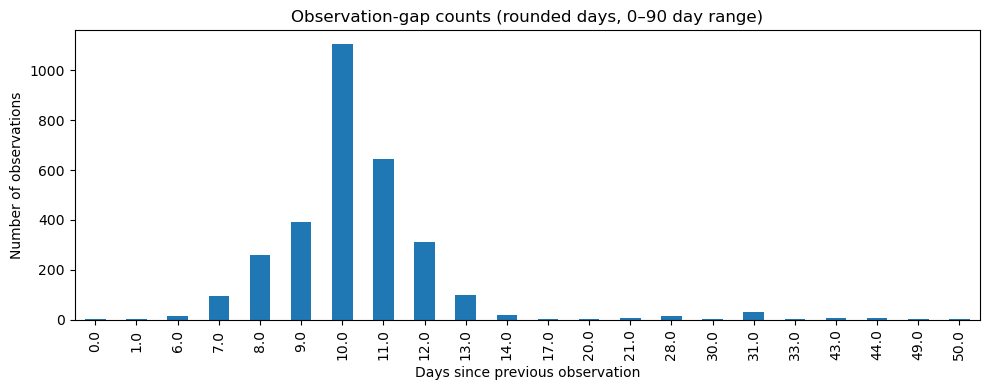

In [10]:
model_source = model_source.sort_values(["Station", "Data Acquisition Time"]).copy()
model_source["gap_days_from_previous"] = (
    model_source.groupby("Station")["Data Acquisition Time"].diff().dt.total_seconds() / 86400
)
print("Dataset date range:", model_source["Data Acquisition Time"].min(), "to", model_source["Data Acquisition Time"].max())
print("\nObservation gap summary (days):")
display(model_source["gap_days_from_previous"].describe().to_frame("gap_days_from_previous"))
gap_counts = model_source["gap_days_from_previous"].round().value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4))
gap_counts.loc[gap_counts.index.to_series().between(0, 90).values].plot(kind="bar", ax=ax)
ax.set_title("Observation-gap counts (rounded days, 0–90 day range)")
ax.set_xlabel("Days since previous observation")
ax.set_ylabel("Number of observations")
plt.tight_layout()
gap_plot_path = OUTPUT_DIR / "ganga_observation_gap_counts.png"
fig.savefig(gap_plot_path, dpi=160, bbox_inches="tight")
plt.show()

## 11. Feature engineering: station-local lagged measurements

In [11]:
# Lag all usable numeric measurements by one observation within each station.
# Predictors at time t therefore come from the preceding row for that same station.
excluded = set(KEYS + METADATA_COLS + ["SlNo", "gap_days_from_previous"])
numeric_measurements = [
    c for c in model_source.columns
    if c not in excluded and pd.api.types.is_numeric_dtype(model_source[c])
]
# Keep targets and numeric measurements; no current-time values are included as features.
feature_frame = model_source[["Station", "Data Acquisition Time", "gap_days_from_previous"] + numeric_measurements].copy()
feature_frame = feature_frame.sort_values(["Station", "Data Acquisition Time"])
lagged = feature_frame[["Station", "Data Acquisition Time", "gap_days_from_previous"]].copy()
for col in numeric_measurements:
    lagged[f"{col}__lag1"] = feature_frame.groupby("Station")[col].shift(1)
lagged["lag1_gap_days"] = feature_frame.groupby("Station")["gap_days_from_previous"].shift(1)

if MIN_GAP_DAYS is not None:
    eligible_gap = lagged["lag1_gap_days"] >= MIN_GAP_DAYS
else:
    eligible_gap = pd.Series(True, index=lagged.index)
if MAX_GAP_DAYS is not None:
    eligible_gap &= lagged["lag1_gap_days"] <= MAX_GAP_DAYS

lagged["year"] = lagged["Data Acquisition Time"].dt.year
lagged["gap_eligible"] = eligible_gap
print("Numeric measurement columns lagged:", len(numeric_measurements))
print("Lagged modelling table shape:", lagged.shape)
print("Rows passing configured past-observation gap filter:", int(eligible_gap.sum()))
print("Gap filter:", MIN_GAP_DAYS, "to", MAX_GAP_DAYS, "days")
display(lagged.head())

Numeric measurement columns lagged: 47
Lagged modelling table shape: (3036, 53)
Rows passing configured past-observation gap filter: 2854
Gap filter: 7 to 14 days


,Station,Data Acquisition Time,gap_days_from_previous,State LGD Code_x__lag1,District LGD Code_x__lag1,Amonia N (mgN/L)__lag1,Boron (mg/L)__lag1,Carbonate (mg/L)__lag1,Calcium (mg/L)__lag1,Chloride (mg/L)__lag1,...,Total Coliform (MPN/100mL)__lag1,State LGD Code__lag1,District LGD Code__lag1,Electric Conductivity (μS/cm)__lag1,Turbidity (NTU)__lag1,Temperature (ºC)__lag1,Total Solids (mg/L)__lag1,lag1_gap_days,year,gap_eligible
487,Allahabad,2021-01-01 07:55:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021,False
488,Allahabad,2021-01-11 08:00:00,10.003472,9.0,120.0,0.07,NaN,39.70,32.47,42.24,...,12000.0,9.0,120.0,340.0,1.9,17.0,NaN,NaN,2021,False
489,Allahabad,2021-01-21 07:40:00,9.986111,9.0,120.0,0.06,NaN,0.00,35.25,39.90,...,14000.0,9.0,120.0,374.0,1.8,19.5,NaN,10.003472,2021,True
490,Allahabad,2021-02-01 08:00:00,11.013889,9.0,120.0,0.07,NaN,0.00,34.21,25.45,...,9300.0,9.0,120.0,325.0,1.5,18.0,NaN,9.986111,2021,True
491,Allahabad,2021-02-11 08:35:00,10.024306,9.0,120.0,0.07,NaN,15.26,40.00,34.87,...,13000.0,9.0,120.0,406.0,1.0,17.5,NaN,11.013889,2021,True


## 12. Chronological train / validation / test split

Each target is trained independently because target availability can differ. Rows are assigned by the timestamp of the value being predicted: training through 2023, validation 2024, and final test 2025. The 2025 test metrics are not used for model selection.

In [12]:
def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)) if len(y_true) >= 2 else np.nan,
        "N": int(len(y_true)),
    }

def apply_gap_filter(frame):
    out = frame[frame["gap_eligible"]].copy()
    return out

## 13. Train the selected candidates and evaluate on 2025

The model choices below were selected using 2024 validation results. Training is then performed through 2024, and 2025 is used as the held-out test set. The persistence comparison uses matching rows where the previous target value is available.

**Interpretation note:** these results are preliminary and cover the eligible station-observations in the configured data. They should not be described as universal river-wide accuracy.


In [13]:

from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

selected_estimators = {
    "BOD": ExtraTreesRegressor(
        n_estimators=400, min_samples_leaf=3, max_features=0.8,
        random_state=42, n_jobs=-1
    ),
    "DO": ExtraTreesRegressor(
        n_estimators=400, min_samples_leaf=3, max_features=0.8,
        random_state=42, n_jobs=-1
    ),
    "pH": HistGradientBoostingRegressor(
        max_iter=200, max_leaf_nodes=15, learning_rate=0.05,
        l2_regularization=1.0, random_state=42
    ),
}

final_models = {}
final_predictions = []
metric_rows = []

for target_label, spec in TARGETS.items():
    target_col = spec["column"]
    lag_target = f"{target_col}__lag1"

    df = lagged.copy()
    df["actual"] = model_source[target_col].values
    df = apply_gap_filter(df).dropna(subset=["actual"]).copy()

    train_df = df[df["year"] <= SPLIT_YEARS["validation"]].copy()
    test_df = df[df["year"] == SPLIT_YEARS["test"]].copy()

    feature_cols = [
        c for c in df.columns
        if c.endswith("__lag1") or c == "lag1_gap_days"
    ]
    feature_cols = [
        c for c in feature_cols
        if c in train_df.columns and train_df[c].notna().any()
    ]

    if train_df.empty or test_df.empty:
        raise ValueError(
            f"{target_label}: empty train/test split. Check date coverage and gap filter."
        )

    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", selected_estimators[target_label]),
    ])
    pipe.fit(train_df[feature_cols], train_df["actual"].astype(float))
    pred = pipe.predict(test_df[feature_cols])
    final_models[target_label] = pipe

    out = test_df[
        ["Station", "Data Acquisition Time", "actual", "lag1_gap_days"]
    ].copy()
    out["target"] = target_label
    out["predicted"] = pred
    out["persistence_prediction"] = (
        pd.to_numeric(test_df[lag_target], errors="coerce")
        if lag_target in test_df.columns else np.nan
    )
    out["persistence_available"] = np.isfinite(
        out["persistence_prediction"].to_numpy(dtype=float)
    )
    final_predictions.append(out)

    metric_rows.append({
        "Target": target_label, "Method": "Selected model",
        "N": len(out),
        "MAE": mean_absolute_error(out["actual"], out["predicted"]),
        "RMSE": np.sqrt(mean_squared_error(out["actual"], out["predicted"])),
        "R2": r2_score(out["actual"], out["predicted"]) if len(out) > 1 else np.nan,
    })

    matched = out[out["persistence_available"]].copy()
    if len(matched) > 1:
        for method, col in [
            ("Selected model (matched)", "predicted"),
            ("Persistence", "persistence_prediction"),
        ]:
            metric_rows.append({
                "Target": target_label, "Method": method,
                "N": len(matched),
                "MAE": mean_absolute_error(matched["actual"], matched[col]),
                "RMSE": np.sqrt(mean_squared_error(matched["actual"], matched[col])),
                "R2": r2_score(matched["actual"], matched[col]),
            })

ganga_metrics = pd.DataFrame(metric_rows)
display(ganga_metrics.round(4))


,Target,Method,N,MAE,RMSE,R2
0,BOD,Selected model,117,1.7539,2.3435,0.2048
1,BOD,Selected model (matched),117,1.7539,2.3435,0.2048
2,BOD,Persistence,117,1.9282,2.6401,-0.0091
3,DO,Selected model,117,0.6376,0.8726,0.2481
4,DO,Selected model (matched),116,0.6398,0.8757,0.2489
5,DO,Persistence,116,0.6207,0.8551,0.2838
6,pH,Selected model,117,0.1101,0.1721,-0.2033
7,pH,Selected model (matched),117,0.1101,0.1721,-0.2033
8,pH,Persistence,117,0.1291,0.2206,-0.9787


## 14. Example predictions
A small preview is provided for demonstration; use the metrics above for evaluation.

In [14]:

for pred_df in final_predictions:
    print(f"\n{pred_df['target'].iloc[0]} — sample 5 predictions")
    display(pred_df[
        ["Station", "Data Acquisition Time", "actual", "predicted",
         "persistence_prediction"]
    ].head(5).round(3))



BOD — sample 5 predictions


,Station,Data Acquisition Time,actual,predicted,persistence_prediction
755,Ankinghat,2025-01-01 09:30:00,4.7,3.818,2.9
756,Ankinghat,2025-01-09 08:45:00,2.5,5.086,4.7
757,Ankinghat,2025-01-21 09:40:00,2.0,3.560,2.5
758,Ankinghat,2025-02-01 10:40:00,1.9,3.295,2.0
759,Ankinghat,2025-02-11 08:15:00,1.3,3.453,1.9



DO — sample 5 predictions


,Station,Data Acquisition Time,actual,predicted,persistence_prediction
755,Ankinghat,2025-01-01 09:30:00,6.1,7.529,7.4
756,Ankinghat,2025-01-09 08:45:00,6.6,6.787,6.1
757,Ankinghat,2025-01-21 09:40:00,7.7,7.676,6.6
758,Ankinghat,2025-02-01 10:40:00,7.1,7.642,7.7
759,Ankinghat,2025-02-11 08:15:00,7.4,7.574,7.1



pH — sample 5 predictions


,Station,Data Acquisition Time,actual,predicted,persistence_prediction
755,Ankinghat,2025-01-01 09:30:00,8.03,8.101,7.97
756,Ankinghat,2025-01-09 08:45:00,8.23,8.190,8.03
757,Ankinghat,2025-01-21 09:40:00,8.34,8.292,8.23
758,Ankinghat,2025-02-01 10:40:00,8.35,8.310,8.34
759,Ankinghat,2025-02-11 08:15:00,8.27,8.313,8.35


In [15]:

# Save the evaluation table and prediction samples to a local artifacts folder.
# Update this path if your AQUA_Data directory is elsewhere.
from pathlib import Path
DEMO_ARTIFACT_DIR = Path(r"C:\Users\ashma\OneDrive\Documents\AQUA_Data\artifacts\ganga_demo")
DEMO_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
ganga_metrics.to_csv(DEMO_ARTIFACT_DIR / "ganga_demo_metrics.csv", index=False)
pd.concat(final_predictions, ignore_index=True).to_csv(
    DEMO_ARTIFACT_DIR / "ganga_demo_predictions.csv", index=False
)
print("Saved demo metrics and predictions to:", DEMO_ARTIFACT_DIR)


Saved demo metrics and predictions to: C:\Users\ashma\OneDrive\Documents\AQUA_Data\artifacts\ganga_demo
